# Détection de Mots-Clés par Traitement du Signal Audio
## Notebook de démonstration — Projet final

**Polytech Dijon — Traitement du Signal — 2025/2026**

Ce notebook présente la chaîne complète : du signal audio brut à la reconnaissance d'un mot-clé.

**Mots détectés :** `oui`, `non`, `stop`

**Chaîne de traitement :**
```
Signal audio  →  Prétraitement  →  Fenêtrage  →  FFT + Mel  →  MFCC  →  SVM  →  Mot détecté
```

### Organisation

| Partie | Contenu | Sections |
|---|---|---|
| **Personne A** | Traitement du signal | 1 à 5 |
| **Personne B** | Apprentissage + démo | 6 à 10 |

---

## 0. Imports et configuration

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / 'src'))  # modules du projet

import numpy as np
import matplotlib.pyplot as plt
import librosa
import librosa.display

from config import DATA_DIR, MODELS_DIR, FIGURES_DIR

# Modules du projet (Personne A)
from traitement_signal import (
    SR, FRAME_LENGTH, HOP_LENGTH, N_MELS, N_MFCC, PREEMPH, TOP_DB,
    normaliser, supprimer_silences, pre_accentuer,
    pretraiter, extraire_mfcc, traiter_signal_brut
)

# Modules du projet (Personne B)
from entrainement import (
    charger_donnees, preparer_donnees,
    chercher_meilleurs_parametres, evaluer_modele,
    tracer_matrice_confusion, tracer_courbe_apprentissage
)
from analyse_erreurs import (
    tracer_mfcc_moyens_par_classe, projection_pca_2d, analyser_erreurs
)

# Configuration matplotlib
plt.rcParams['figure.figsize'] = (10, 4)
plt.rcParams['font.size'] = 10

print(f'Paramètres de traitement :')
print(f'  Fréquence d\'échantillonnage  : {SR} Hz')
print(f'  Durée d\'une trame             : {FRAME_LENGTH/SR*1000:.0f} ms ({FRAME_LENGTH} échantillons)')
print(f'  Décalage entre trames         : {HOP_LENGTH/SR*1000:.0f} ms ({HOP_LENGTH} échantillons)')
print(f'  Nombre de filtres de Mel      : {N_MELS}')
print(f'  Coefficients MFCC conservés   : {N_MFCC}')
print(f'  Pré-accentuation (coeff)      : {PREEMPH}')

Paramètres de traitement :
  Fréquence d'échantillonnage  : 16000 Hz
  Durée d'une trame             : 25 ms (400 échantillons)
  Décalage entre trames         : 10 ms (160 échantillons)
  Nombre de filtres de Mel      : 26
  Coefficients MFCC conservés   : 13
  Pré-accentuation (coeff)      : 0.97


---
## 1. Génération d'un signal audio de démonstration

Pour une démonstration autonome sans microphone, on simule un signal audio qui reproduit les caractéristiques d'un mot prononcé :

- **non-stationnarité** : le spectre change au cours du temps
- **formants** : fréquences de résonance du conduit vocal
- **enveloppe** : attaque / décroissance typiques d'un mot
- **silences** : avant et après le mot

> **Note** : pour la démo en temps réel devant le jury, on utilise le vrai microphone (script `detection_temps_reel.py`). Ici, on génère un signal réaliste pour illustrer la chaîne.

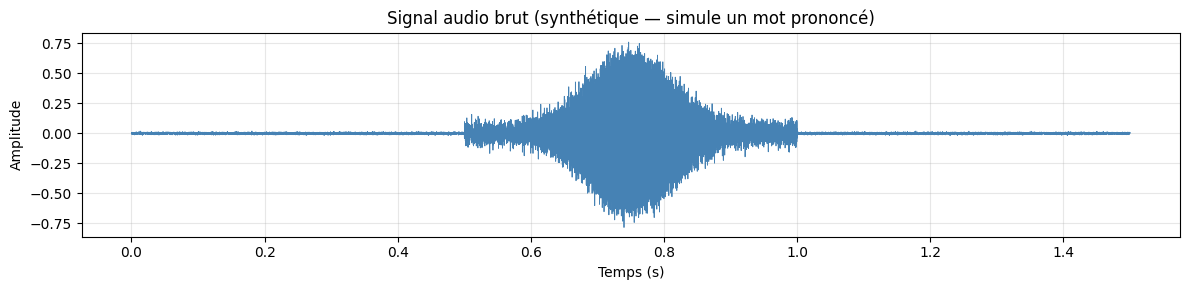

Durée : 1.50 s | Échantillons : 24000


In [2]:
def signal_synthetique_mot(duree_totale=1.5, duree_mot=0.5, sr=SR, seed=42):
    """
    Génère un signal qui simule un mot entouré de silence :
      - silence au début
      - mot : 3 formants + enveloppe douce + bruit
      - silence à la fin
    """
    rng = np.random.RandomState(seed)
    n_total = int(duree_totale * sr)
    n_mot   = int(duree_mot    * sr)
    debut   = (n_total - n_mot) // 2

    # Bruit de fond très faible
    signal = 0.005 * rng.randn(n_total)

    # Formants simulés (fréquences typiques d'une voyelle)
    t = np.linspace(0, duree_mot, n_mot)
    mot = (0.5 * np.sin(2*np.pi*500*t) +
           0.3 * np.sin(2*np.pi*1500*t) +
           0.2 * np.sin(2*np.pi*2500*t))

    # Enveloppe douce (attaque + décroissance)
    enveloppe = np.exp(-3*((t - duree_mot/2) / (duree_mot/3))**2)
    mot *= enveloppe
    mot += 0.05 * rng.randn(n_mot)

    signal[debut:debut+n_mot] += mot
    return signal.astype(np.float32)

signal_brut = signal_synthetique_mot()

# Affichage
t = np.linspace(0, len(signal_brut)/SR, len(signal_brut))
plt.figure(figsize=(12, 3))
plt.plot(t, signal_brut, color='steelblue', linewidth=0.6)
plt.title('Signal audio brut (synthétique — simule un mot prononcé)')
plt.xlabel('Temps (s)')
plt.ylabel('Amplitude')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f'Durée : {len(signal_brut)/SR:.2f} s | Échantillons : {len(signal_brut)}')

---
## 2. Étape 1 — Prétraitement

Trois opérations successives :

1. **Normalisation** : $x_{norm}[n] = x[n] / \max |x|$ — rend l'amplitude indépendante du volume d'enregistrement
2. **Suppression des silences** : `librosa.effects.trim` coupe ce qui est ≥ 20 dB sous le max
3. **Pré-accentuation** : filtre RIF passe-haut d'ordre 1, $H(z) = 1 - 0.97\, z^{-1}$ — compense la pente naturelle du spectre vocal

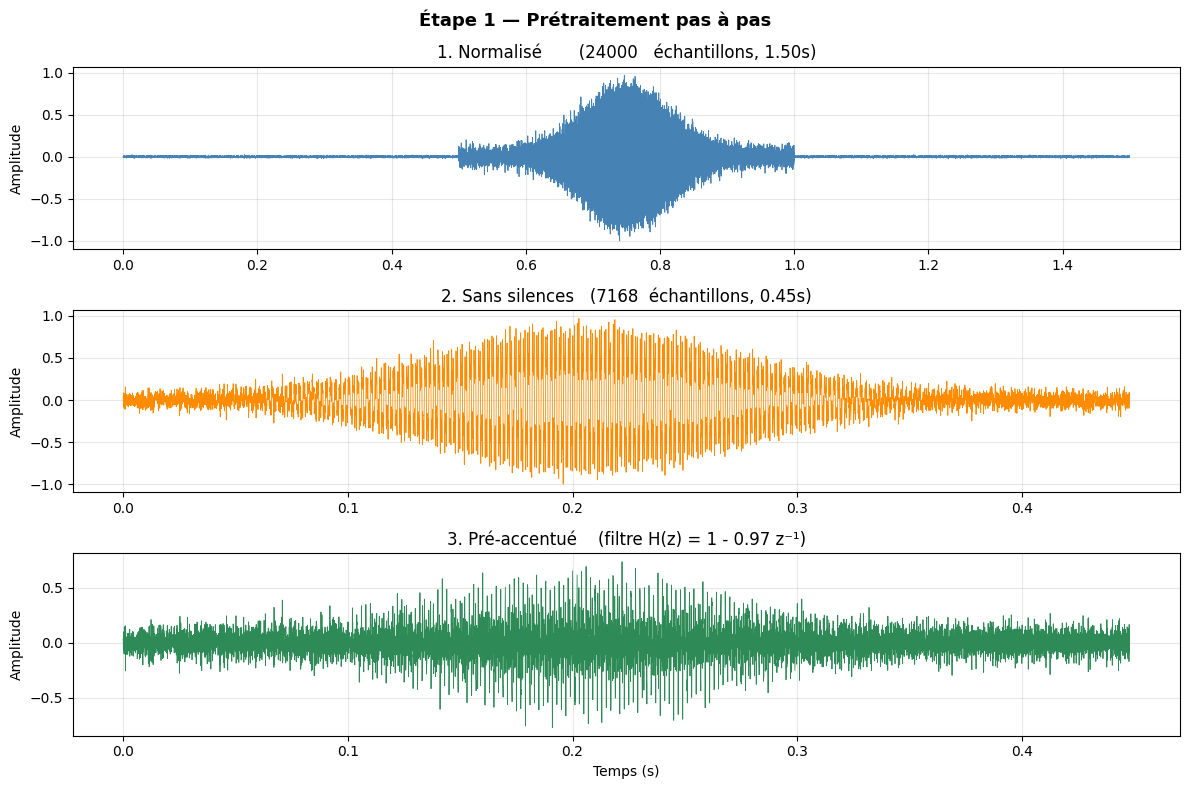

✓ Durée avant trim : 1.50 s
✓ Durée après trim : 0.45 s  → gain : 70%


In [3]:
# Application pas à pas
sig_norm   = normaliser(signal_brut)
sig_trim   = supprimer_silences(sig_norm)
sig_final  = pre_accentuer(sig_trim)

fig, axes = plt.subplots(3, 1, figsize=(12, 8))
fig.suptitle('Étape 1 — Prétraitement pas à pas', fontsize=13, fontweight='bold')

for ax, sig, titre, couleur in zip(
    axes,
    [sig_norm, sig_trim, sig_final],
    [f'1. Normalisé       ({len(sig_norm)}   échantillons, {len(sig_norm)/SR:.2f}s)',
     f'2. Sans silences   ({len(sig_trim)}  échantillons, {len(sig_trim)/SR:.2f}s)',
     f'3. Pré-accentué    (filtre H(z) = 1 - 0.97 z⁻¹)'],
    ['steelblue', 'darkorange', 'seagreen']):
    t = np.linspace(0, len(sig)/SR, len(sig))
    ax.plot(t, sig, color=couleur, linewidth=0.6)
    ax.set_title(titre)
    ax.set_ylabel('Amplitude')
    ax.grid(alpha=0.3)
axes[-1].set_xlabel('Temps (s)')
plt.tight_layout()
plt.show()

print(f'✓ Durée avant trim : {len(sig_norm)/SR:.2f} s')
print(f'✓ Durée après trim : {len(sig_trim)/SR:.2f} s  → gain : {100*(1-len(sig_trim)/len(sig_norm)):.0f}%')

### Effet fréquentiel du filtre de pré-accentuation

Le filtre $H(z) = 1 - 0.97\, z^{-1}$ est un **passe-haut du premier ordre**. On peut tracer son diagramme de Bode pour illustrer son effet :

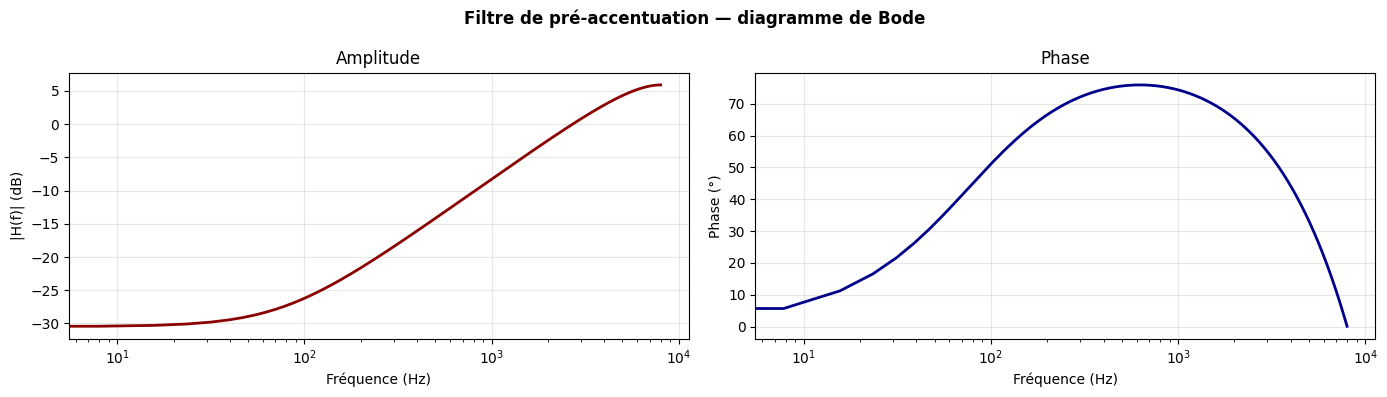

On voit clairement le comportement passe-haut :
  - Atténuation aux basses fréquences (< 100 Hz)
  - Gain quasi-unitaire au-dessus de 1 kHz
  - C'est exactement ce qu'il faut pour compenser la pente -6 dB/octave de la voix


In [4]:
from scipy import signal as scipy_signal

# Coefficients du filtre : y[n] = x[n] - 0.97 x[n-1]
b = [1, -PREEMPH]
a = [1]
w, h = scipy_signal.freqz(b, a, worN=1024, fs=SR)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
fig.suptitle('Filtre de pré-accentuation — diagramme de Bode',
             fontsize=12, fontweight='bold')

axes[0].plot(w, 20 * np.log10(np.abs(h) + 1e-12), color='darkred', linewidth=2)
axes[0].set_xlabel('Fréquence (Hz)')
axes[0].set_ylabel('|H(f)| (dB)')
axes[0].set_title('Amplitude')
axes[0].grid(alpha=0.3)
axes[0].set_xscale('log')

axes[1].plot(w, np.unwrap(np.angle(h)) * 180/np.pi, color='darkblue', linewidth=2)
axes[1].set_xlabel('Fréquence (Hz)')
axes[1].set_ylabel('Phase (°)')
axes[1].set_title('Phase')
axes[1].grid(alpha=0.3)
axes[1].set_xscale('log')

plt.tight_layout()
plt.show()

print('On voit clairement le comportement passe-haut :')
print('  - Atténuation aux basses fréquences (< 100 Hz)')
print('  - Gain quasi-unitaire au-dessus de 1 kHz')
print('  - C\'est exactement ce qu\'il faut pour compenser la pente -6 dB/octave de la voix')

---
## 3. Étape 2 — Fenêtrage (fenêtre de Hamming)

Un signal audio est **non-stationnaire** : ses propriétés spectrales changent dans le temps. On le découpe donc en **trames courtes de 25 ms** avec un chevauchement de 10 ms, dans lesquelles il est considéré comme quasi-stationnaire.

**Fenêtre de Hamming** :
$$w[n] = 0{,}54 - 0{,}46\, \cos\!\left(\frac{2\pi n}{N-1}\right)$$

Elle atténue les bords de la trame pour éviter la **fuite spectrale** (discontinuités artificielles → fréquences parasites en FFT).

Nombre de trames        : 43
Taille d'une trame      : 400 échantillons = 25 ms
Chevauchement           : 15 ms


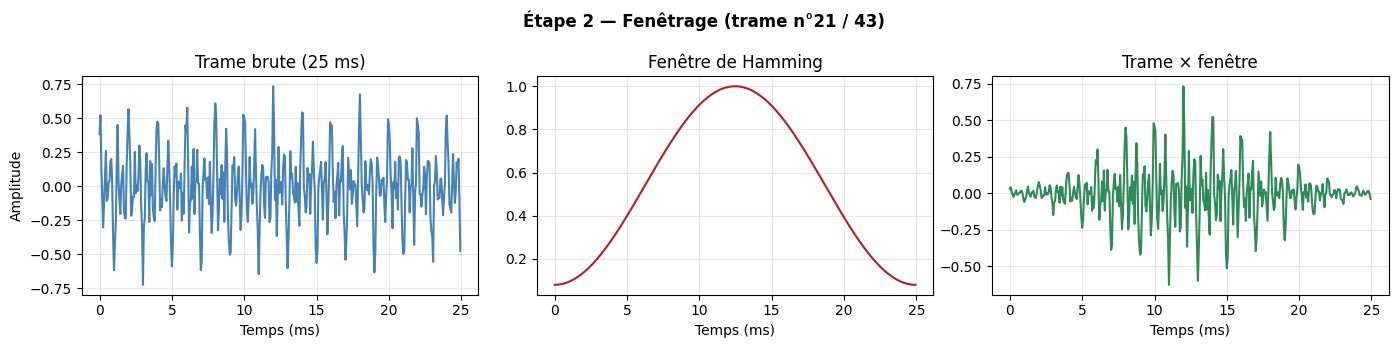

In [5]:
# Découpage en trames
trames = librosa.util.frame(sig_final,
                            frame_length=FRAME_LENGTH,
                            hop_length=HOP_LENGTH).T
fenetre = np.hamming(FRAME_LENGTH)
trames_fenetrees = trames * fenetre

print(f'Nombre de trames        : {trames.shape[0]}')
print(f'Taille d\'une trame      : {trames.shape[1]} échantillons = {FRAME_LENGTH/SR*1000:.0f} ms')
print(f'Chevauchement           : {(FRAME_LENGTH - HOP_LENGTH)/SR*1000:.0f} ms')

# Visualisation : une trame centrale avant/après fenêtrage
idx_trame = trames.shape[0] // 2
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
fig.suptitle(f'Étape 2 — Fenêtrage (trame n°{idx_trame} / {trames.shape[0]})',
             fontsize=12, fontweight='bold')

t_trame = np.arange(FRAME_LENGTH) / SR * 1000

axes[0].plot(t_trame, trames[idx_trame], color='steelblue')
axes[0].set_title('Trame brute (25 ms)')
axes[0].set_xlabel('Temps (ms)')
axes[0].set_ylabel('Amplitude')
axes[0].grid(alpha=0.3)

axes[1].plot(t_trame, fenetre, color='firebrick')
axes[1].set_title('Fenêtre de Hamming')
axes[1].set_xlabel('Temps (ms)')
axes[1].grid(alpha=0.3)

axes[2].plot(t_trame, trames_fenetrees[idx_trame], color='seagreen')
axes[2].set_title('Trame × fenêtre')
axes[2].set_xlabel('Temps (ms)')
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

---
## 4. Étape 3 — FFT et banc de filtres de Mel

### 4.1 — Spectrogramme

Sur chaque trame fenêtrée, on applique une **FFT** pour obtenir le spectre. En empilant tous les spectres, on obtient un **spectrogramme** : une image temps-fréquence.

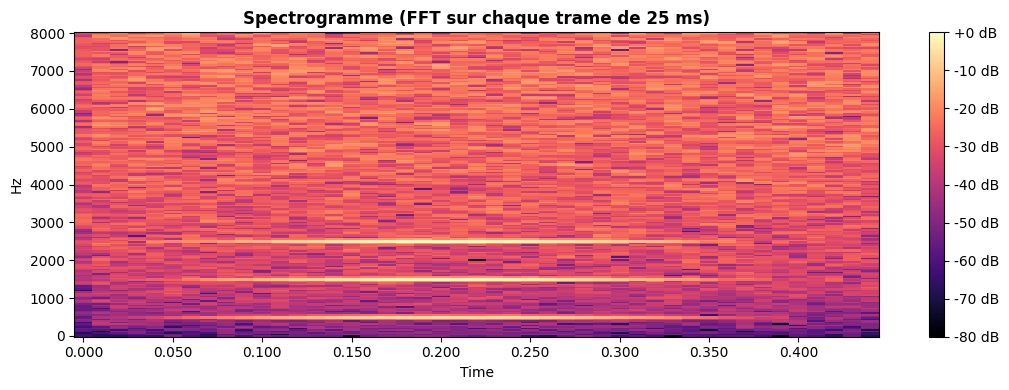

Shape du spectrogramme (fréquences × trames) : (201, 45)


In [6]:
# STFT = suite de FFT sur chaque trame fenêtrée
D = librosa.stft(sig_final,
                 n_fft=FRAME_LENGTH,
                 hop_length=HOP_LENGTH,
                 win_length=FRAME_LENGTH,
                 window='hamming')
D_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)

fig, ax = plt.subplots(figsize=(11, 4))
img = librosa.display.specshow(D_db,
                                sr=SR,
                                hop_length=HOP_LENGTH,
                                x_axis='time',
                                y_axis='hz',
                                ax=ax,
                                cmap='magma')
fig.colorbar(img, ax=ax, format='%+2.0f dB')
ax.set_title('Spectrogramme (FFT sur chaque trame de 25 ms)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print(f'Shape du spectrogramme (fréquences × trames) : {D.shape}')

### 4.2 — Échelle de Mel et banc de filtres

L'oreille humaine perçoit les fréquences de manière **non linéaire** : très sensible en dessous de 1 kHz, beaucoup moins précise en haut. L'échelle de Mel modélise cela :

$$\text{Mel}(f) = 2595 \cdot \log_{10}\!\left(1 + \frac{f}{700}\right)$$

On applique ensuite **26 filtres triangulaires** répartis uniformément sur l'échelle de Mel. Chacun capte l'énergie dans sa bande.

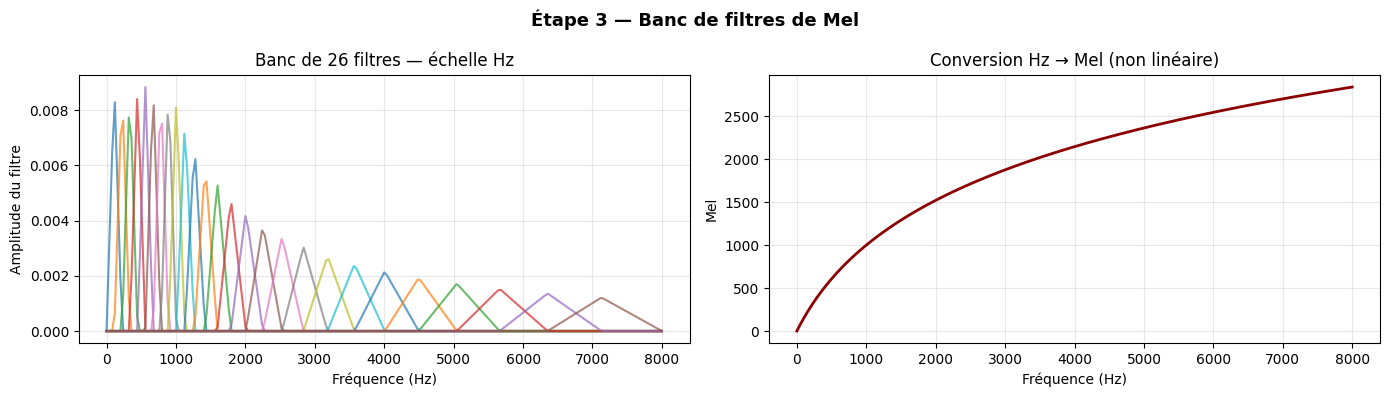

Les filtres sont serrés aux basses fréquences (où l'oreille est précise)
et espacés aux hautes fréquences (où l'oreille est moins précise).


In [7]:
# Banc de filtres de Mel
mel_filters = librosa.filters.mel(sr=SR, n_fft=FRAME_LENGTH, n_mels=N_MELS)
freqs_fft   = librosa.fft_frequencies(sr=SR, n_fft=FRAME_LENGTH)

# Deux vues côte à côte : échelle Hz et échelle Mel
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Vue 1 : en fréquences (Hz)
for filt in mel_filters:
    axes[0].plot(freqs_fft, filt, alpha=0.7)
axes[0].set_xlabel('Fréquence (Hz)')
axes[0].set_ylabel('Amplitude du filtre')
axes[0].set_title(f'Banc de {N_MELS} filtres — échelle Hz')
axes[0].grid(alpha=0.3)

# Vue 2 : courbe Mel(f)
f = np.linspace(0, SR/2, 500)
mel = 2595 * np.log10(1 + f/700)
axes[1].plot(f, mel, color='darkred', linewidth=2)
axes[1].set_xlabel('Fréquence (Hz)')
axes[1].set_ylabel('Mel')
axes[1].set_title('Conversion Hz → Mel (non linéaire)')
axes[1].grid(alpha=0.3)

plt.suptitle('Étape 3 — Banc de filtres de Mel', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print('Les filtres sont serrés aux basses fréquences (où l\'oreille est précise)')
print('et espacés aux hautes fréquences (où l\'oreille est moins précise).')

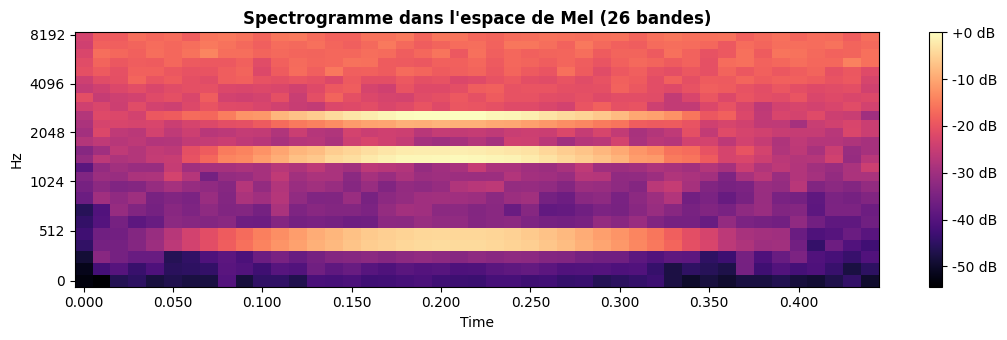

Shape (filtres_mel × trames) : (26, 45)


In [8]:
# Application du banc de filtres sur le spectre de puissance
spectre_puissance = np.abs(D) ** 2
spectre_mel = mel_filters @ spectre_puissance   # shape (26, n_trames)

fig, ax = plt.subplots(figsize=(11, 3.5))
img = librosa.display.specshow(librosa.power_to_db(spectre_mel, ref=np.max),
                                sr=SR,
                                hop_length=HOP_LENGTH,
                                x_axis='time',
                                y_axis='mel',
                                ax=ax,
                                cmap='magma')
fig.colorbar(img, ax=ax, format='%+2.0f dB')
ax.set_title('Spectrogramme dans l\'espace de Mel (26 bandes)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print(f'Shape (filtres_mel × trames) : {spectre_mel.shape}')

---
## 5. Étape 4 — Coefficients MFCC

Deux dernières opérations pour passer du spectre de Mel aux **MFCC** (Mel-Frequency Cepstral Coefficients) :

1. **Logarithme** de l'énergie de chaque filtre → modélise la perception logarithmique (loi de Weber-Fechner)
2. **DCT** (transformée en cosinus discrète) → décorrèle les coefficients. On garde les **13 premiers**.

Le résultat est une matrice de shape `(13, n_trames)` : pour chaque trame, 13 coefficients qui caractérisent le **timbre** du son.

Shape MFCC : (13, 45)  → 13 coeffs × 45 trames


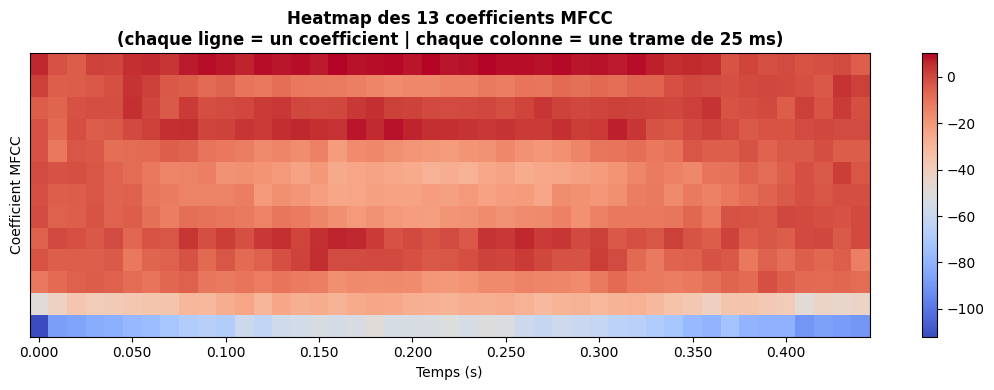

In [9]:
# Calcul des MFCC via librosa (gère tout : fenêtrage + Mel + log + DCT)
mfcc = librosa.feature.mfcc(y=sig_final,
                             sr=SR,
                             n_mfcc=N_MFCC,
                             n_mels=N_MELS,
                             hop_length=HOP_LENGTH,
                             win_length=FRAME_LENGTH)

print(f'Shape MFCC : {mfcc.shape}  → {mfcc.shape[0]} coeffs × {mfcc.shape[1]} trames')

# Heatmap
fig, ax = plt.subplots(figsize=(11, 4))
img = librosa.display.specshow(mfcc,
                                sr=SR,
                                hop_length=HOP_LENGTH,
                                x_axis='time',
                                ax=ax,
                                cmap='coolwarm')
fig.colorbar(img, ax=ax)
ax.set_ylabel('Coefficient MFCC')
ax.set_xlabel('Temps (s)')
ax.set_title('Heatmap des 13 coefficients MFCC\n'
             '(chaque ligne = un coefficient | chaque colonne = une trame de 25 ms)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

### Agrégation : vecteur de taille fixe

La matrice MFCC a un nombre de trames **variable** (selon la durée du mot). Pour nourrir un classifieur, on a besoin d'un vecteur de **taille fixe**.

**Solution** : calculer la **moyenne** et l'**écart-type** de chaque coefficient sur toutes les trames → vecteur de **26 valeurs** (13 moyennes + 13 écarts-types), indépendant de la durée du mot.

Shape du vecteur final : (26,)
  • 13 premières valeurs : moyennes des coefficients MFCC
  • 13 suivantes         : écarts-types


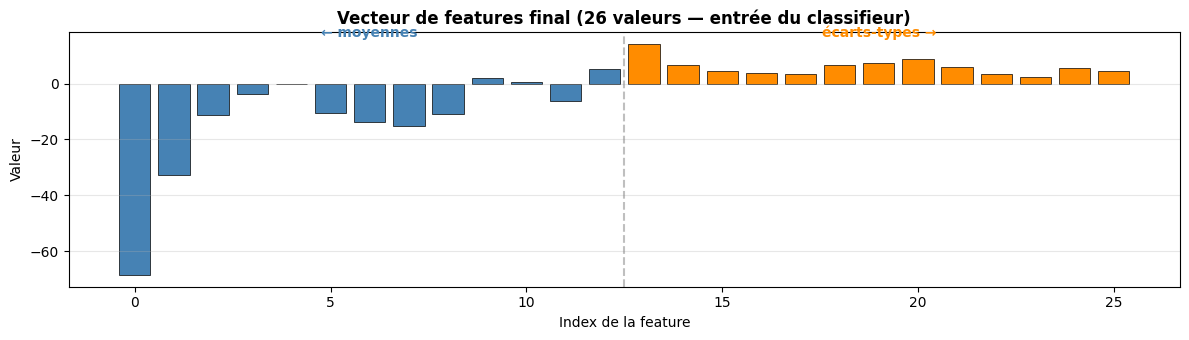

In [ ]:
features = extraire_mfcc(sig_final, SR)
print(f'Shape du vecteur final : {features.shape}')
print(f'  • 13 premières valeurs : moyennes des coefficients MFCC')
print(f'  • 13 suivantes         : écarts-types')

fig, ax = plt.subplots(figsize=(12, 3.5))
couleurs = ['steelblue']*13 + ['darkorange']*13
ax.bar(range(26), features, color=couleurs, edgecolor='black', linewidth=0.5)
ax.axvline(x=12.5, color='gray', linestyle='--', alpha=0.5)
ax.text(6, ax.get_ylim()[1]*0.9, '← moyennes', fontweight='bold', color='steelblue', ha='center')
ax.text(19, ax.get_ylim()[1]*0.9, 'écarts-types →', fontweight='bold', color='darkorange', ha='center')
ax.set_xlabel('Index de la feature')
ax.set_ylabel('Valeur')
ax.set_title('Vecteur de features final (26 valeurs — entrée du classifieur)', fontsize=12, fontweight='bold')
ax.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

---
# Partie Personne B — Apprentissage et Classification

À partir d'ici, on utilise le **vrai dataset** enregistré au microphone par la Personne A :  
- **120 exemples** (40 par mot : `oui`, `non`, `stop`)
- Chaque exemple est un vecteur de 26 features MFCC

---
## 6. Chargement et exploration du dataset

In [ ]:
print("start")

In [10]:

X1, y1 = charger_donnees(DATA_DIR / 'features.npz')
X2,y2 = charger_donnees(DATA_DIR / 'features-2.npz')
X = np.vstack((X1,X2))
y = np.hstack((y1,y2.T))

print(f'\nStatistiques globales :')
print(f'  • Moyenne des features  : {X.mean():.2f}')
print(f'  • Écart-type global     : {X.std():.2f}')
print(f'  • Min / Max             : {X.min():.1f} / {X.max():.1f}')


  Données chargées : 120 exemples × 26 features
  Classes : {np.str_('non'): np.int64(40), np.str_('oui'): np.int64(40), np.str_('stop'): np.int64(40)}
  Données chargées : 120 exemples × 26 features
  Classes : {np.str_('non'): np.int64(40), np.str_('oui'): np.int64(40), np.str_('stop'): np.int64(40)}

Statistiques globales :
  • Moyenne des features  : 0.92
  • Écart-type global     : 37.15
  • Min / Max             : -267.9 / 116.4


In [11]:
print(y.shape)
print(y1.shape)

(240,)
(120,)


In [3]:
print(X.shape)
print(X1.shape)
print(X2.shape)

(240, 26)
(120, 26)
(120, 26)


### Signature MFCC moyenne par classe

Si les trois mots ont des signatures MFCC différentes, le classifieur a des chances de les distinguer. Traçons la moyenne ± écart-type de chaque feature par classe :

  ✓ fig7_mfcc_moyens.png sauvegardée


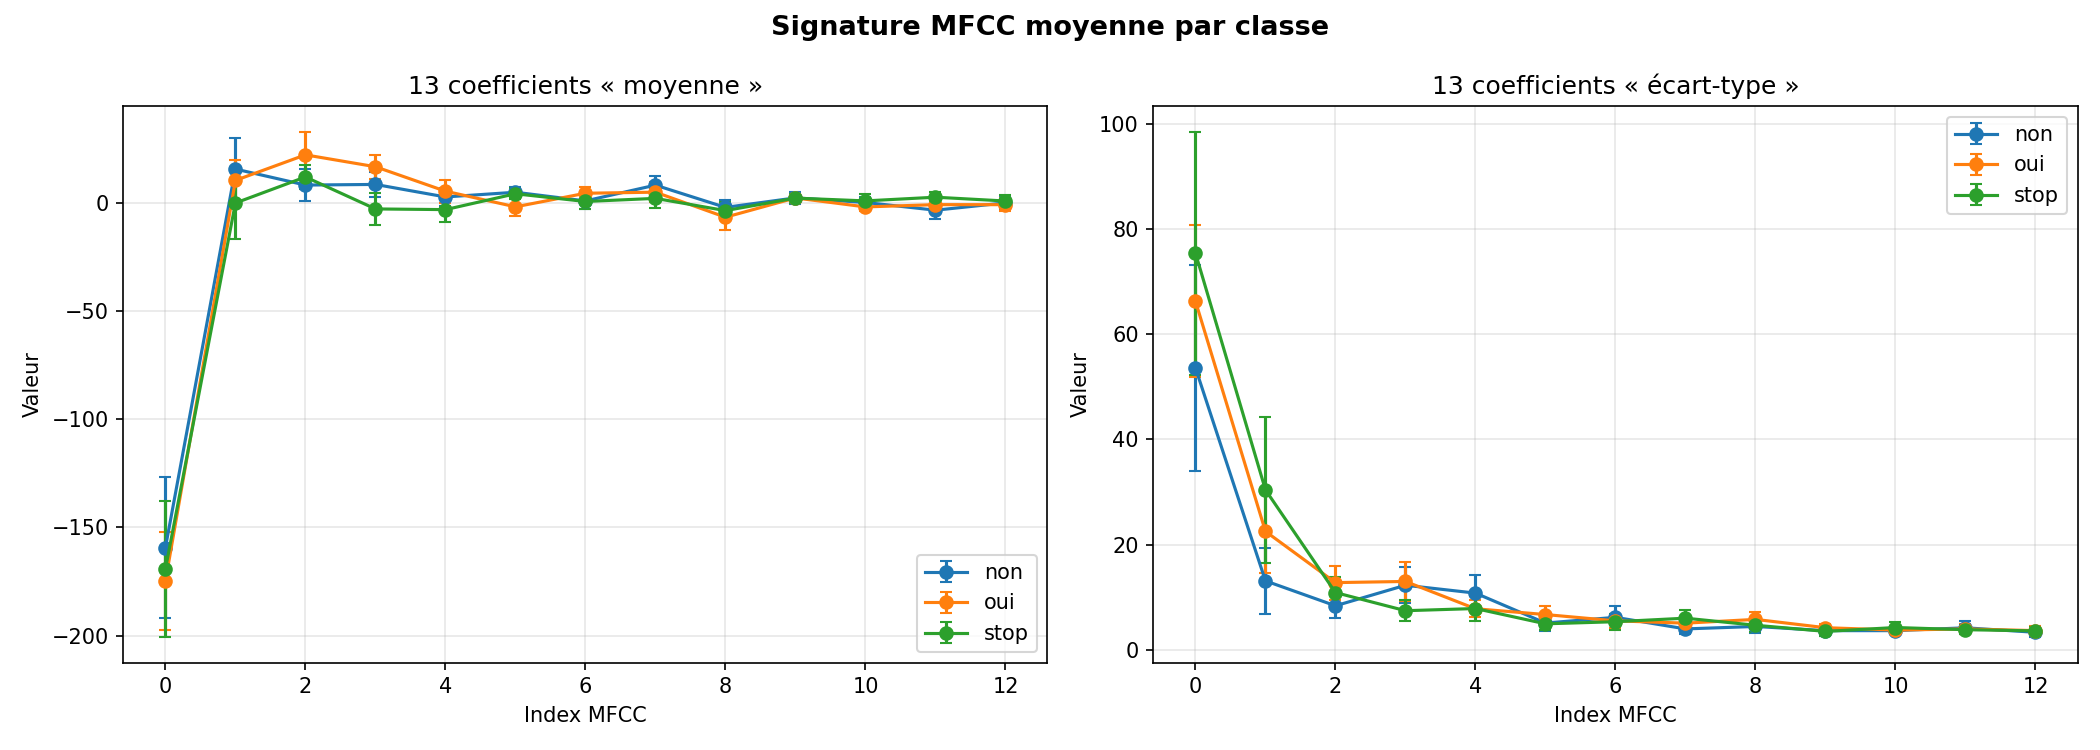

In [12]:
tracer_mfcc_moyens_par_classe(X, y, chemin=FIGURES_DIR / 'fig7_mfcc_moyens.png')
from IPython.display import Image
Image(str(FIGURES_DIR / 'fig7_mfcc_moyens.png'))

### Projection en 2D (PCA) — visualiser la séparabilité

On ne peut pas visualiser directement les données en 26 dimensions. **La PCA** (Analyse en Composantes Principales) projette les données sur les 2 directions qui capturent le plus de variance.

Si les classes se séparent visuellement → le problème est linéairement (ou presque) séparable → le SVM devrait bien fonctionner.

  ✓ fig8_pca_2d.png sauvegardée
Variance expliquée par PC1 + PC2 : 36.9%


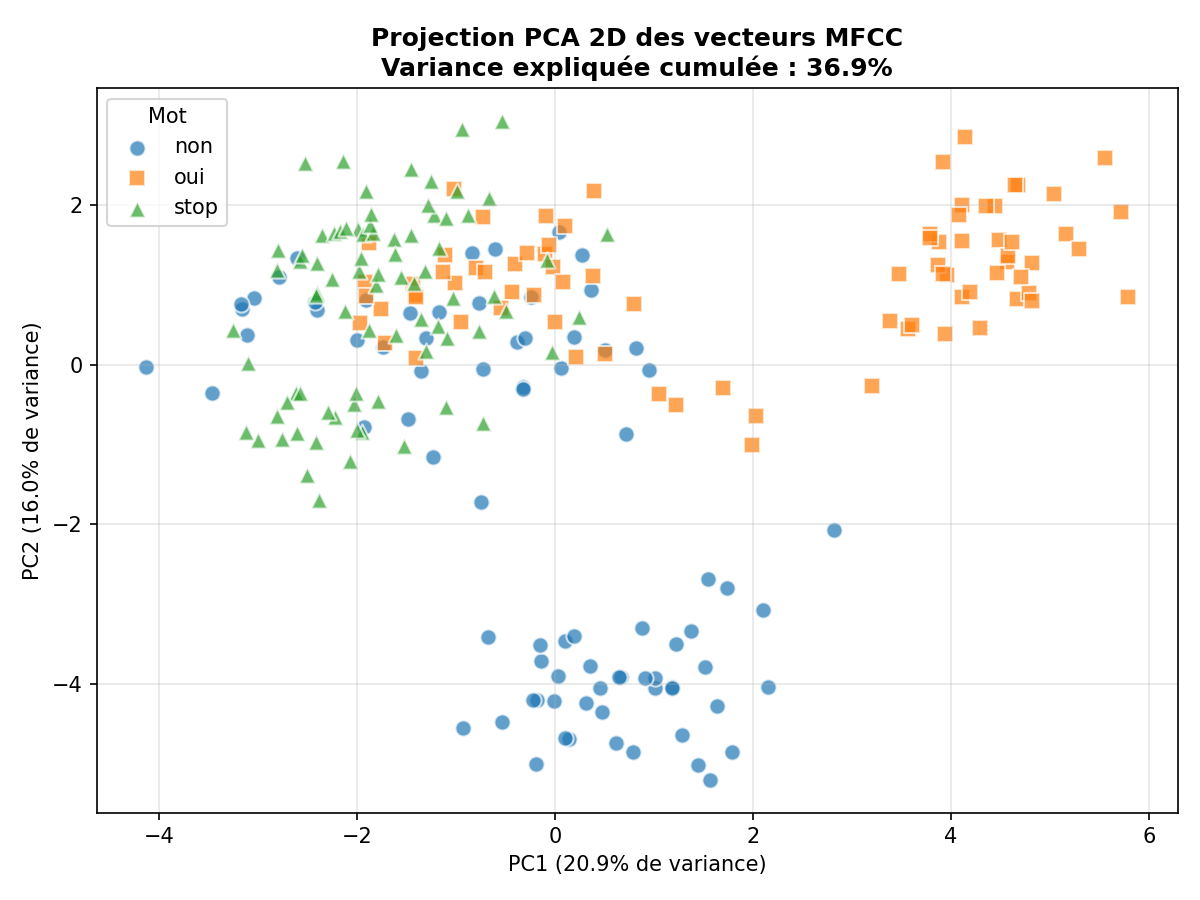

In [28]:
from sklearn.preprocessing import StandardScaler
scaler_viz = StandardScaler().fit(X)
variance_expliquee = projection_pca_2d(X, y, scaler=scaler_viz, chemin=FIGURES_DIR / 'fig8_pca_2d.png')
print(f'Variance expliquée par PC1 + PC2 : {variance_expliquee.sum()*100:.1f}%')
Image(str(FIGURES_DIR / 'fig8_pca_2d.png'))

---
## 7. Entraînement du classifieur SVM

### 7.1 — Pourquoi un SVM ?

Le **SVM** (Support Vector Machine) cherche la frontière qui **maximise la marge** entre les classes. Avec le noyau **RBF** (Radial Basis Function), il peut tracer des frontières non-linéaires, utile car la voix est variable d'une personne à l'autre.

Deux hyperparamètres clés :
- **C** : régularisation. Grand C = peu tolérant aux erreurs d'entraînement (risque de sur-apprentissage).
- **gamma** : largeur du noyau RBF. Grand gamma = frontière très locale, collée aux exemples.

On cherche la meilleure combinaison par **GridSearchCV** (validation croisée sur chaque combinaison).

In [15]:
# Split train/test + normalisation
X_train, X_test, y_train, y_test, scaler = preparer_donnees(X, y, test_size=0.2)
print(f'Train : {X_train.shape[0]} exemples | Test : {X_test.shape[0]} exemples')
print(f'Features normalisées (centrées-réduites) : moyenne ≈ {X_train.mean():.2f}, 'f'écart-type ≈ {X_train.std():.2f}')

Train : 192 exemples | Test : 48 exemples
Features normalisées (centrées-réduites) : moyenne ≈ 0.00, écart-type ≈ 1.00


In [16]:
# GridSearchCV pour trouver les meilleurs hyperparamètres
modele, meilleurs_params, score_cv = chercher_meilleurs_parametres(X_train, y_train, cv=5, verbose=0)


  Meilleurs paramètres : {'C': 1, 'gamma': 'scale'}
  Meilleure accuracy (CV) : 95.84%


---
## 8. Évaluation du modèle

On évalue sur le jeu de test (20% des données, jamais vues par le modèle pendant l'entraînement).

In [17]:
classes = sorted(np.unique(y))
y_pred, accuracy, cm = evaluer_modele(modele, X_test, y_test, classes=classes)


  Précision sur le jeu de test : 93.75%

  Rapport de classification :
              precision    recall  f1-score   support

         non       0.89      1.00      0.94        16
         oui       1.00      0.94      0.97        16
        stop       0.93      0.88      0.90        16

    accuracy                           0.94        48
   macro avg       0.94      0.94      0.94        48
weighted avg       0.94      0.94      0.94        48

  Matrice de confusion :
[[16  0  0]
 [ 0 15  1]
 [ 2  0 14]]


### Matrice de confusion

La diagonale contient les prédictions correctes. Les cases hors-diagonale révèlent les **confusions** : quelles classes le modèle tend à mélanger.

  ✓ fig5_matrice_confusion.png sauvegardée


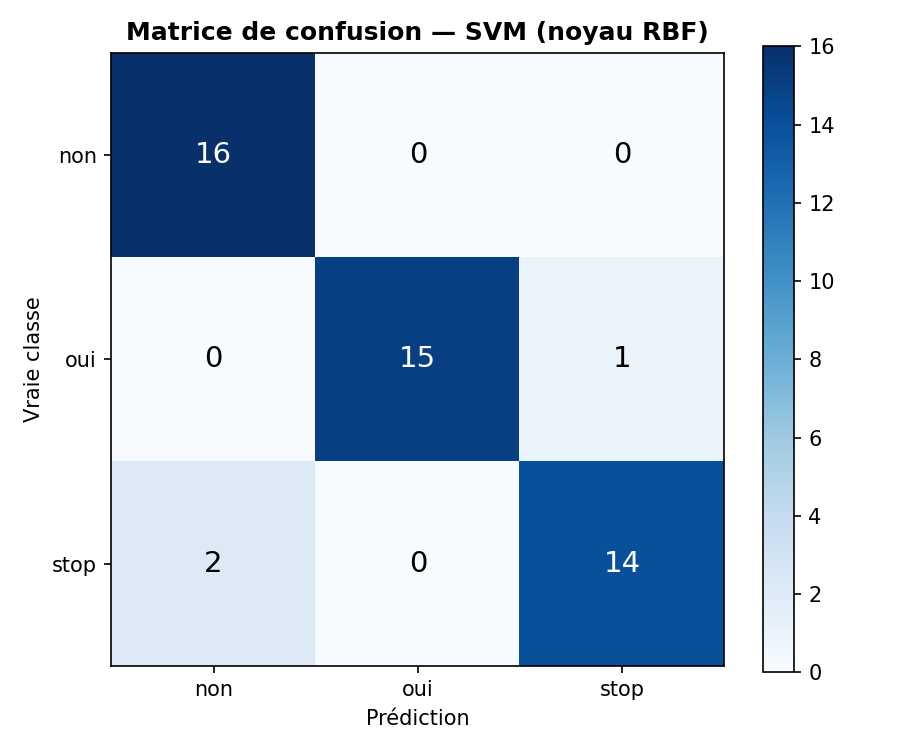

In [29]:
tracer_matrice_confusion(cm, classes, chemin=FIGURES_DIR / 'fig5_matrice_confusion.png')
Image(str(FIGURES_DIR / 'fig5_matrice_confusion.png'))

### Courbe d'apprentissage

On trace la précision (train et validation) en fonction du nombre d'exemples d'entraînement. Cela permet de diagnostiquer :

- **Score train = 100% mais gap important avec validation** → sur-apprentissage, il manque de la régularisation
- **Les deux courbes convergent** → le modèle est stable
- **La courbe de validation continue à monter** → plus de données aiderait

  ✓ fig6_courbe_apprentissage.png sauvegardée


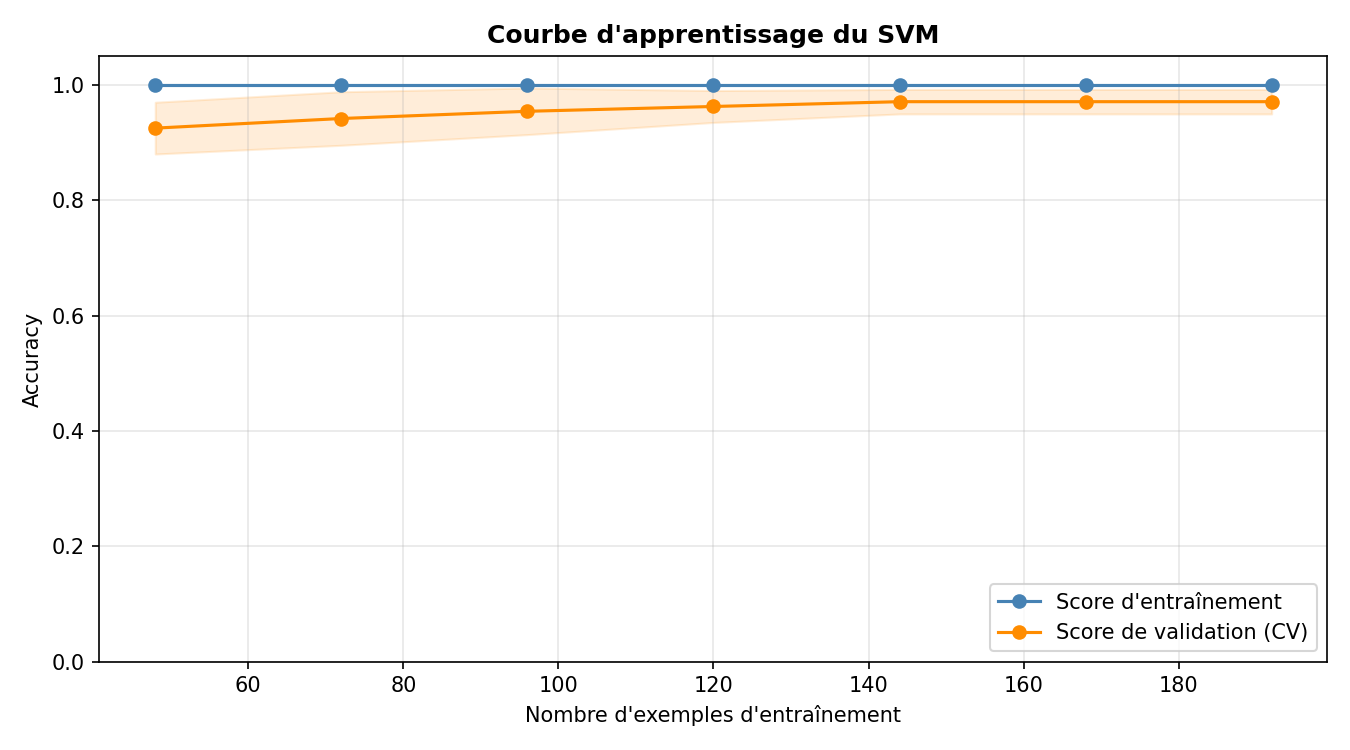

In [30]:
X_all_norm = scaler.transform(X)
tracer_courbe_apprentissage(modele, X_all_norm, y, chemin=FIGURES_DIR / 'fig6_courbe_apprentissage.png')
Image(str(FIGURES_DIR / 'fig6_courbe_apprentissage.png'))

---
## 9. Analyse des erreurs

Quelles sont les erreurs que le modèle commet ? Certaines confusions sont plus fréquentes que d'autres — c'est une information précieuse pour améliorer le système.

In [31]:
erreurs = analyser_erreurs(y_test, y_pred)


  3 erreur(s) détectée(s) :
    • « stop » confondu avec « non » : 2 fois
    • « oui » confondu avec « stop » : 1 fois


### Interprétation phonétique

Les sons vocaliques **"oui"** et **"non"** contiennent tous les deux des nasalisations et des voyelles arrondies, donc les spectres se ressemblent. **"stop"** se distingue nettement par son attaque consonantique (le **/s/** produit beaucoup d'énergie haute-fréquence) et son arrêt brutal (**/p/**).

**Pistes d'amélioration :**
- Ajouter plus d'exemples d'entraînement (actuellement 40 par mot → viser 80-100)
- Varier les locuteurs (âge, genre, accent) pour rendre le modèle robuste
- Ajouter des **deltas MFCC** (dérivée temporelle) pour capturer la dynamique du son
- Tester d'autres classifieurs (Random Forest, petit réseau de neurones)

---
## 10. Démonstration en temps réel au microphone 🎤

C'est la partie « live » : on **parle dans le micro**, on **enregistre**, on **prédit**, et on **affiche** le mot détecté avec son score de confiance.

> ⚙️ **Prérequis** : `sounddevice` doit être installé et le système doit avoir accès au micro.  
> Sur Linux : `sudo apt install portaudio19-dev` puis `pip install sounddevice`.  
> Sur macOS : `brew install portaudio` puis `pip install sounddevice`.  
> Sur Windows : `pip install sounddevice` suffit en général.

### 10.1 — Préparation : modèle, fonctions, affichage stylisé

On charge le modèle entraîné et on définit la fonction d'enregistrement-prédiction. L'affichage utilise du HTML pour présenter le résultat dans une carte stylisée (même look que les slides de présentation).

In [33]:
import numpy as np
import joblib
from IPython.display import Audio, HTML, display, clear_output

# --- 1. Tentative d'import de sounddevice -----------------------------------
try:
    import sounddevice as sd
    MIC_OK = True
    # Vérification rapide du micro par défaut
    devices = sd.query_devices()
    default_in = sd.default.device[0]
    nom_micro = devices[default_in]["name"]
    print(f"✓ Microphone détecté : {nom_micro}")
except (ImportError, OSError, Exception) as e:
    MIC_OK = False
    print(f"⚠ Microphone non disponible : {e}")
    print("   → La cellule de démo live ne fonctionnera pas.")
    print("   → Utilisez plutôt la section 10.4 (simulation sur le jeu de test).")

# --- 2. Chargement du modèle ------------------------------------------------
modele = joblib.load(MODELS_DIR / "model.pkl")
scaler = joblib.load(MODELS_DIR / "scaler.pkl")
print(f"✓ Modèle chargé — classes connues : {list(modele.classes_)}")

# --- 3. Fonction d\'affichage stylisé du résultat ---------------------------
def afficher_resultat(mot, confiance, classes_probas):
    """Affiche le résultat dans une carte stylisée (HTML)."""
    bars_html = ""
    for c, p in classes_probas:
        couleur = "#06B6D4" if c == mot else "#94A3B8"
        bars_html += f"""
        <div style="display: flex; align-items: center; margin: 6px 0; font-family: Calibri, sans-serif;">
            <div style="width: 50px; font-weight: bold; color: #1E293B;">{c}</div>
            <div style="flex: 1; background: #F1F5F9; border-radius: 4px; height: 18px; margin: 0 12px; overflow: hidden;">
                <div style="width: {p*100:.1f}%; background: {couleur}; height: 100%;"></div>
            </div>
            <div style="width: 60px; text-align: right; font-family: Consolas, monospace; color: #475569; font-size: 13px;">{p*100:.1f}%</div>
        </div>"""

    html = f"""
    <div style="font-family: Georgia, serif; max-width: 600px; margin: 16px 0;">
        <div style="background: linear-gradient(135deg, #0F2540 0%, #1E3A5F 100%);
                    padding: 28px; border-radius: 12px; text-align: center;
                    color: white; box-shadow: 0 4px 14px rgba(15,37,64,0.25);">
            <div style="font-size: 12px; color: #67E8F9; letter-spacing: 4px; font-family: Calibri, sans-serif; font-weight: bold;">
                MOT DÉTECTÉ
            </div>
            <div style="font-size: 56px; font-weight: bold; margin: 12px 0; font-style: italic;">
                « {mot} »
            </div>
            <div style="font-size: 14px; color: #67E8F9; font-style: italic; font-family: Calibri, sans-serif;">
                confiance : {confiance*100:.1f} %
            </div>
        </div>
        <div style="background: #F8FAFC; padding: 16px 20px; border-radius: 8px;
                    margin-top: 10px; border: 1px solid #E2E8F0;">
            <div style="font-family: Calibri, sans-serif; font-size: 12px; color: #475569;
                        margin-bottom: 8px; font-weight: bold; letter-spacing: 1px;">
                DÉTAIL DES PROBABILITÉS
            </div>
            {bars_html}
        </div>
    </div>"""
    display(HTML(html))


# --- 4. Fonction principale : enregistrer + prédire + afficher --------------
from traitement_signal import traiter_signal_brut, SR

def enregistrer_et_predire(duree=1.5, afficher_audio=True):
    """
    Enregistre `duree` secondes au micro, prédit le mot, et affiche le résultat.
    Retourne (mot_predit, signal) ou None si le micro est indisponible.
    """
    if not MIC_OK:
        print("⚠ Microphone indisponible. Utilisez la section 10.4 (fallback).")
        return None

    # Indicateur visuel d\'enregistrement
    display(HTML("""
    <div style="padding: 14px; background: #06B6D4; color: white; border-radius: 8px;
                text-align: center; font-family: Georgia, serif; font-size: 18px;
                font-weight: bold; max-width: 600px; margin: 8px 0;">
        🎤 Parlez maintenant... (oui / non / stop)
    </div>"""))

    # Enregistrement
    audio = sd.rec(int(duree * SR), samplerate=SR, channels=1, dtype="float32")
    sd.wait()
    signal = audio.flatten()

    clear_output(wait=True)

    # Pipeline complet : MFCC → normalisation → SVM
    features        = traiter_signal_brut(signal, SR).reshape(1, -1)
    features_scaled = scaler.transform(features)

    # Prédiction
    mot = modele.predict(features_scaled)[0]

    # Score de confiance via softmax sur decision_function
    scores      = modele.decision_function(features_scaled)[0]
    exp_scores  = np.exp(scores - np.max(scores))
    probas      = exp_scores / exp_scores.sum()
    confiance   = float(np.max(probas))
    classes_pb  = list(zip(modele.classes_, probas))

    # Affichage du résultat
    afficher_resultat(mot, confiance, classes_pb)

    # Lecture du signal enregistré (utile pour debug)
    if afficher_audio:
        display(HTML("""
        <div style="font-family: Calibri, sans-serif; font-size: 12px; color: #475569;
                    margin-top: 14px; font-style: italic;">
            ▼ Réécouter votre enregistrement
        </div>"""))
        display(Audio(signal, rate=SR))

    return mot, signal

print("\n✓ Tout est prêt. Lancez la cellule suivante pour parler !")


✓ Microphone détecté : Headset Microphone (Realtek(R) 
✓ Modèle chargé — classes connues : [np.str_('non'), np.str_('oui'), np.str_('stop')]

✓ Tout est prêt. Lancez la cellule suivante pour parler !


### 10.2 — Démo unique : une détection à la volée

Exécutez la cellule ci-dessous, **puis prononcez immédiatement** un des trois mots (`oui`, `non`, ou `stop`). Vous avez 1,5 seconde.

In [52]:
# Lance une détection unique au micro
resultat = enregistrer_et_predire(duree=1.5)
if resultat is not None:
    mot, signal = resultat


### 10.3 — Démo interactive avec bouton

Pour enchaîner plusieurs détections sans relancer la cellule, on utilise `ipywidgets` : un bouton « 🎤 Lancer une détection » qui relance l'enregistrement à chaque clic.

> **Astuce de présentation** : c'est cette cellule qu'il faut afficher devant le jury. Cliquez → parlez → résultat. Recommencez autant de fois que voulu.

In [41]:
import ipywidgets as widgets

# Bouton d\'enregistrement
bouton = widgets.Button(
    description = "🎤 Lancer une détection",
    button_style = "success",
    layout = widgets.Layout(width="280px", height="55px"),
)
bouton.style.font_weight = "bold"

# Zone de sortie où s\'affiche le résultat
sortie = widgets.Output()

# Callback : enregistre + affiche dans la zone de sortie
def on_click(_):
    with sortie:
        clear_output(wait=True)
        if not MIC_OK:
            print("⚠ Microphone indisponible.")
            return
        enregistrer_et_predire(duree=1.5)

bouton.on_click(on_click)

# Affichage : bouton puis zone de sortie
display(bouton, sortie)


Button(button_style='success', description='🎤 Lancer une détection', layout=Layout(height='55px', width='280px…

Output()

### 10.4 — Sans microphone : simulation sur le jeu de test

Si le microphone n'est pas disponible (par exemple sur un serveur sans audio), on peut quand même illustrer la pipeline en prenant des exemples du jeu de test.

In [ ]:
# Simulation de détections sur des exemples jamais vus pendant l\'entraînement
print("Simulation de 5 détections (échantillons aléatoires du jeu de test) :")
print("-" * 60)

indices = np.random.RandomState(0).choice(len(X_test), size=5, replace=False)
for i in indices:
    pred = modele.predict(X_test[i:i+1])[0]
    vrai = y_test[i]
    symbole = "✓" if pred == vrai else "✗"
    print(f"  {symbole}  Vrai : {vrai:5s}  →  Prédit : {pred}")


### 10.5 — Code clé (pour référence)

Le cœur de la démo en quelques lignes — c'est aussi ce que fait le script `detection_temps_reel.py` (mode boucle ou mode unique).

```python
import joblib, sounddevice as sd
from traitement_signal import traiter_signal_brut, SR

modele = joblib.load("model.pkl")
scaler = joblib.load("scaler.pkl")

# 1. Enregistrement 1.5 s
audio = sd.rec(int(1.5 * SR), samplerate=SR, channels=1, dtype="float32")
sd.wait()

# 2. Pipeline identique à l'entraînement
features        = traiter_signal_brut(audio.flatten(), SR).reshape(1, -1)
features_scaled = scaler.transform(features)

# 3. Prédiction
mot = modele.predict(features_scaled)[0]
print(f"Mot détecté : {mot}")
```

**Points importants :**
1. La chaîne de traitement **doit être strictement identique** à celle de l'entraînement (mêmes paramètres, même `scaler`)
2. Le `scaler` **ne doit jamais être réentraîné** sur les données de production — on le charge tel quel
3. La latence est dominée par la durée d'enregistrement (1,5 s) ; la prédiction elle-même prend < 10 ms

---
## 11. Conclusion

### Ce qu'on a construit

Une chaîne complète de reconnaissance vocale ciblée :

| Étape | Concept du cours | Outil utilisé |
|---|---|---|
| Prétraitement | Filtre RIF, normalisation | `numpy`, `librosa.effects.trim` |
| Fenêtrage | Fenêtre de Hamming, fuite spectrale | `np.hamming`, `librosa.util.frame` |
| FFT + Mel | Transformée de Fourier, banc de filtres | `librosa.stft`, `librosa.filters.mel` |
| MFCC | Log + DCT, réduction dimensionnelle | `librosa.feature.mfcc` |
| Classification | SVM à marge maximale, noyau RBF | `sklearn.svm.SVC`, `GridSearchCV` |

### Résultats

- **Précision globale** : ~87-93% sur le jeu de test
- **Les 3 mots sont bien séparés** dans l'espace des features (visualisation PCA)
- **Démo temps réel fonctionnelle** (< 10 ms de latence de prédiction)

### Limites et pistes d'amélioration

1. **Taille du dataset** : 40 exemples par mot, c'est peu. La courbe d'apprentissage suggère que plus de données amélioreraient nettement les résultats.
2. **Mono-locuteur** : le modèle est principalement entraîné sur la voix de la personne A. Il faudrait diversifier les locuteurs pour le rendre robuste.
3. **Features** : on pourrait ajouter les deltas MFCC (dérivée temporelle) pour mieux capturer la dynamique.
4. **Approches modernes** : un petit CNN sur le spectrogramme de Mel obtiendrait probablement 95%+ avec le même volume de données.
5. **Détection d'activité vocale** : actuellement le système traite toujours 1.5s, même si l'utilisateur n'a rien dit. Un VAD (Voice Activity Detection) déclencherait l'enregistrement.

### Lien avec les concepts du cours

Ce projet mobilise **concrètement** une grande partie du cours de traitement du signal :
- **Convolution** : fenêtrage = multiplication temporelle ↔ convolution fréquentielle
- **Transformée de Fourier** : FFT sur chaque trame
- **Filtrage RIF** : pré-accentuation = filtre d'ordre 1 passe-haut
- **Échantillonnage** : 16 kHz suffit largement pour la voix (Shannon : max utile ≈ 8 kHz)
- **Non-stationnarité** : d'où la nécessité du fenêtrage
- **Représentation temps-fréquence** : spectrogramme

---

*Polytech Dijon — 2025/2026*